In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

In [18]:
df = pd.read_csv(r"C:\Users\shiva\Downloads\archive (1).csv")
cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
real = df[cols].values.astype(float)

print(df.shape)
df[cols].describe()

(200, 5)


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


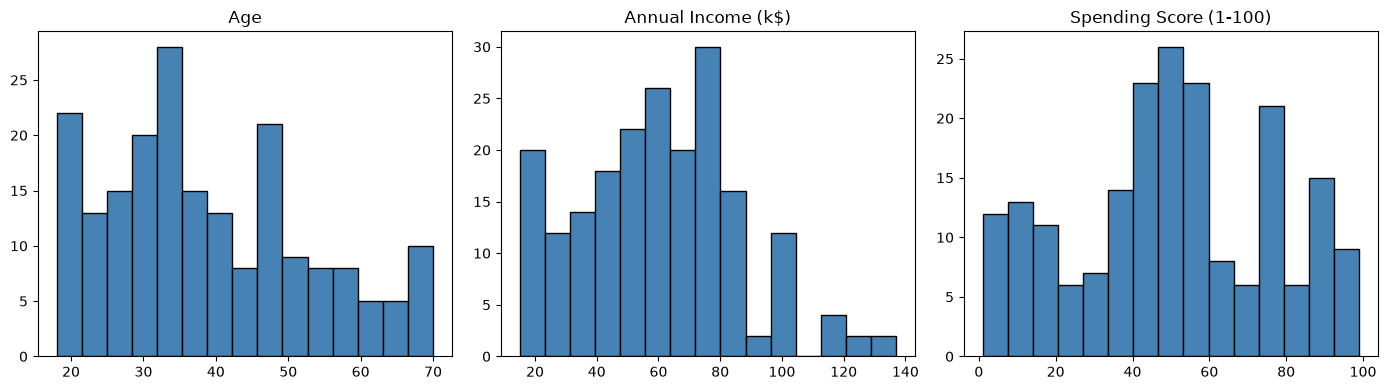

                         Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.00               -0.01                   -0.33
Annual Income (k$)     -0.01                1.00                    0.01
Spending Score (1-100) -0.33                0.01                    1.00


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for i, c in enumerate(cols):
    ax[i].hist(df[c], bins=15, color="steelblue", edgecolor="black")
    ax[i].set_title(c)
plt.tight_layout()
plt.show()

print(df[cols].corr().round(2))

In [4]:
def fit(X):
    mean = X.mean(axis=0)
    cov = np.cov(X, rowvar=False, bias=True) + 1e-6 * np.eye(X.shape[1])
    return mean, cov

def sample(mean, cov, n):
    return np.random.multivariate_normal(mean, cov, n)

def kl_gauss(m0, c0, m1, c1):
    # KL( real || generation ) for multivariate Gaussians
    k = len(m0)
    c1_inv = np.linalg.inv(c1)
    diff = m1 - m0
    term1 = np.trace(c1_inv @ c0)
    term2 = diff @ c1_inv @ diff
    term3 = np.linalg.slogdet(c1)[1] - np.linalg.slogdet(c0)[1]
    return 0.5 * (term1 + term2 - k + term3)

m_real, c_real = fit(real)

In [5]:
GENERATIONS = 100
N = 50          # samples per generation (smaller = faster collapse)
REAL_FRAC = 0.3 # share of real data mixed in for the control run
SNAP = [0, 10, 50, 100]

### Objective 2

In [6]:
def run_pure():
    X = real[np.random.choice(len(real), N, replace=False)]
    stds, kls, snaps = [], [], {}
    for g in range(GENERATIONS + 1):
        m, c = fit(X)
        stds.append(np.sqrt(np.diag(c)))
        kls.append(kl_gauss(m_real, c_real, m, c))
        if g in SNAP:
            snaps[g] = X.copy()
        X = sample(m, c, N)
    return np.array(stds), np.array(kls), snaps

std_pure, kl_pure, snaps_pure = run_pure()
print("Std at Gen 0  :", std_pure[0].round(2))
print("Std at Gen 100:", std_pure[-1].round(2))

Std at Gen 0  : [13.62 24.56 24.27]
Std at Gen 100: [ 6.23 10.56 13.98]


In [7]:
# OBJECTIVE 4
def run_mixed():
    X = real[np.random.choice(len(real), N, replace=False)]
    stds, kls = [], []
    n_real = int(REAL_FRAC * N)
    for g in range(GENERATIONS + 1):
        m, c = fit(X)
        stds.append(np.sqrt(np.diag(c)))
        kls.append(kl_gauss(m_real, c_real, m, c))
        synth = sample(m, c, N - n_real)
        fresh = real[np.random.choice(len(real), n_real, replace=False)]
        X = np.vstack([synth, fresh])
    return np.array(stds), np.array(kls)

std_mix, kl_mix = run_mixed()
print("Std at Gen 100 (mixed):", std_mix[-1].round(2))

Std at Gen 100 (mixed): [13.11 26.11 27.95]


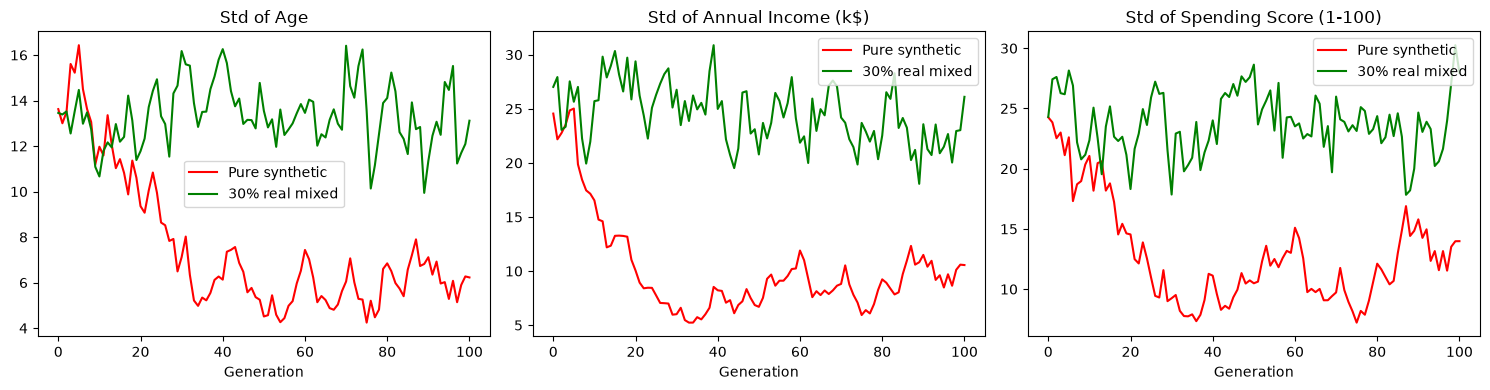

In [8]:
#Objective 3
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(cols):
    ax[i].plot(std_pure[:, i], label="Pure synthetic", color="red")
    ax[i].plot(std_mix[:, i], label=f"{int(REAL_FRAC*100)}% real mixed", color="green")
    ax[i].set_title(f"Std of {c}")
    ax[i].set_xlabel("Generation")
    ax[i].legend()
plt.tight_layout()
plt.show()

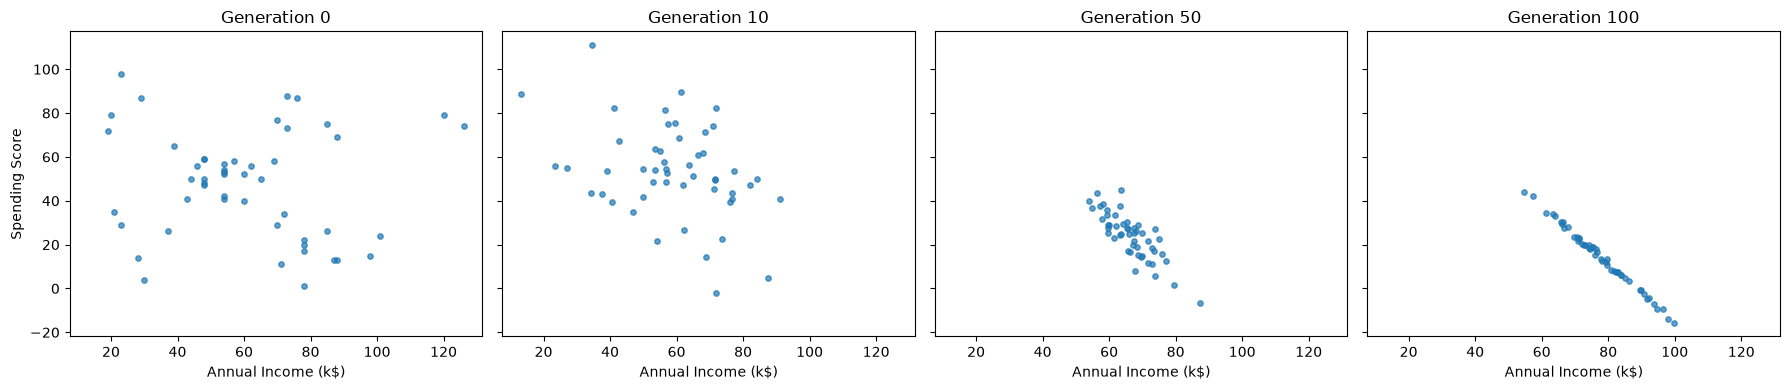

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)
for a, g in zip(ax, SNAP):
    X = snaps_pure[g]
    a.scatter(X[:, 1], X[:, 2], s=15, alpha=0.7)
    a.set_title(f"Generation {g}")
    a.set_xlabel("Annual Income (k$)")
ax[0].set_ylabel("Spending Score")
plt.tight_layout()
plt.show()

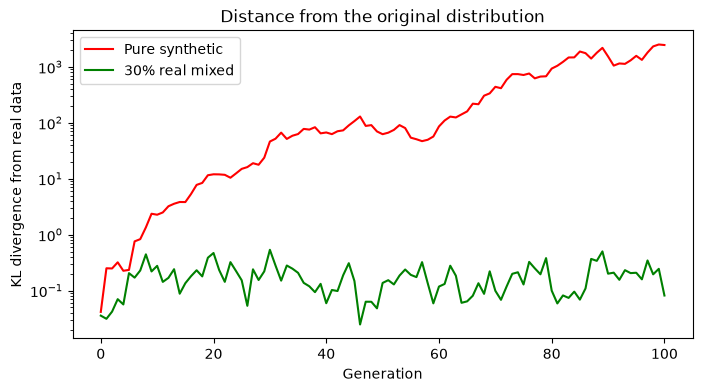

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(kl_pure, label="Pure synthetic", color="red")
plt.plot(kl_mix, label=f"{int(REAL_FRAC*100)}% real mixed", color="green")
plt.xlabel("Generation")
plt.ylabel("KL divergence from real data")
plt.title("Distance from the original distribution")
plt.legend()
plt.yscale("log")
plt.show()

In [11]:
summary = pd.DataFrame({
    "Run": ["Pure synthetic", "Mixed with real"],
    "Avg std Gen 0": [std_pure[0].mean().round(2)] * 2,
    "Avg std Gen 100": [std_pure[-1].mean().round(2), std_mix[-1].mean().round(2)],
    "KL Gen 100": [round(kl_pure[-1], 3), round(kl_mix[-1], 3)],
})
summary

,Run,Avg std Gen 0,Avg std Gen 100,KL Gen 100
0,Pure synthetic,20.82,10.26,2460.610
1,Mixed with real,20.82,22.39,0.082


In [12]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: C:\Users\shiva
Files available: ['-1.14-windows.xml', '.anaconda', '.anaconda-desktop', '.android', '.cache', '.conda', '.condarc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.Ld2VirtualBox', '.Ld9VirtualBox', '.mamba', '.openjfx', '0)', '3D Objects', 'ansel', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'count', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'generation_0_train.csv', 'IBA_IOAPDATA', 'Links', 'Local Settings', 'mumu_boot.txt', 'Music', 'My Documents', 'name.match(numberRegex)[0]', 'NetHood', 'new', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{36e22033-bc66-11ef-a272-e3d563d86e6f}.TM.blf', 'NTUSER.DAT{36e22033-bc66-11ef-a272-e3d563d86e6f}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{36e22033-bc66-11ef-a272-e3d563d86e6f}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'prac1ml.ipynb', 'prac5cv.ipynb', 'PrintHood', 'projectMC.ipynb', 'Recent', 'Saved Games', 'Searches', 'Se

In [13]:
import os

downloads = r"C:\Users\shiva\Downloads"

for file in os.listdir(downloads):
    if "mall" in file.lower() or file.lower().endswith(".csv"):
        print(file)

archive (1).csv
India-Tourism-Statistics-2021-Table-5.2.3.csv


In [19]:
import pandas as pd

df = pd.read_csv(r"C:\Users\shiva\Downloads\archive (1).csv")

print("Dataset loaded successfully!")
print(df.head())
print("Column names:", df.columns.tolist())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Column names: ['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Dataset shape: (200, 5)


## OBJECTIVE 1

Silhouette Score: 0.555


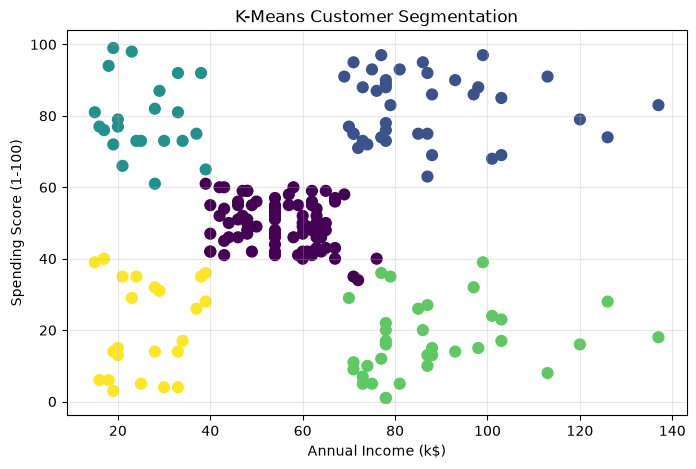

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
5        2  
6        4  
7        2  
8        4  
9        2  

Customers in each cluster:
Cluster
0    8

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Load dataset
np.random.seed(42)

df = pd.read_csv(
    r"C:\Users\shiva\Downloads\archive (1).csv"
)

# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Calculate silhouette score
score = silhouette_score(X_scaled, df["Cluster"])
print("Silhouette Score:", round(score, 3))

# Visualize customer segments
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis",
    s=60
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segmentation")
plt.grid(True, alpha=0.3)
plt.show()

# Display sample results
print(df.head(10))

# Display the number of customers in each cluster
print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

## OBJECTIVE 2

           Real  Pure synthetic (Gen 100)  Mixed with real (Gen 100)
Segment 1  40.5                      16.0                       44.0
Segment 2  19.5                       0.0                       16.0
Segment 3  11.0                       0.0                        4.0
Segment 4  17.5                      84.0                       22.0
Segment 5  11.5                       0.0                       14.0
Segments with at least 5% of customers: [np.int64(5), np.int64(2), np.int64(4)]


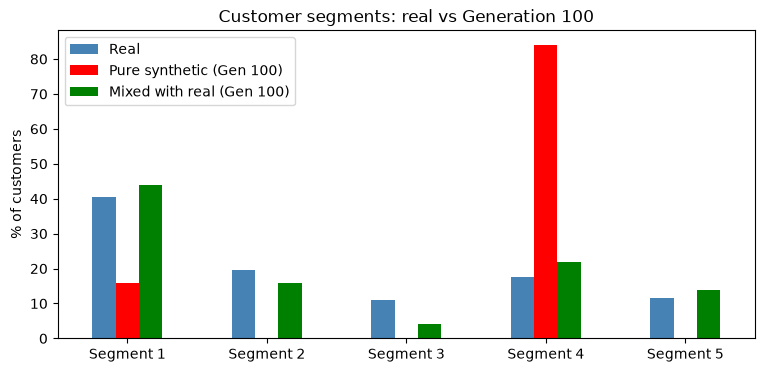

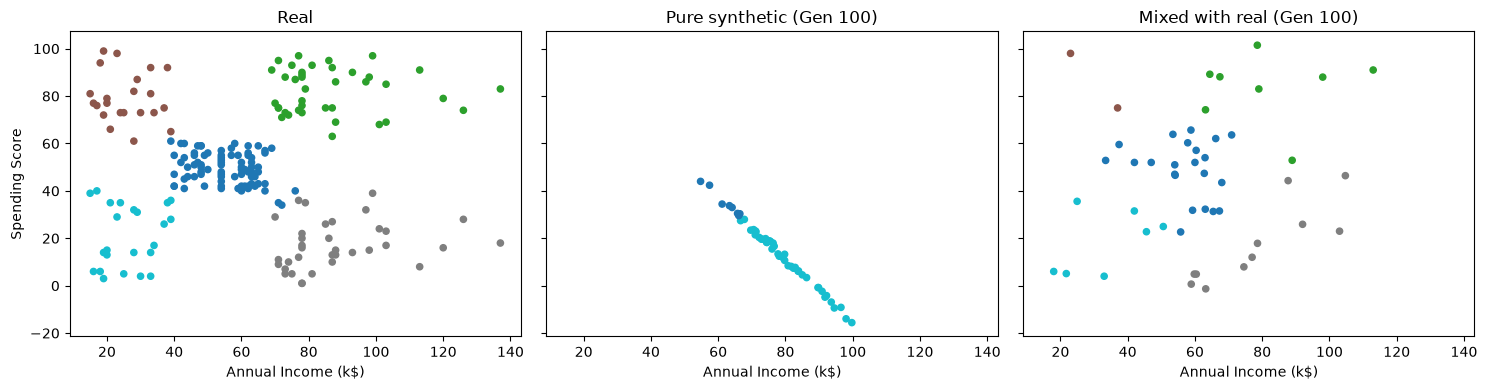

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
df = pd.read_csv(r"C:\Users\shiva\Downloads\archive (1).csv")
real = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values.astype(float)

scaler = StandardScaler().fit(real[:, 1:3])
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(scaler.transform(real[:, 1:3]))

# simulation (same as before)
def fit(X): return X.mean(0), np.cov(X, rowvar=False, bias=True) + 1e-6 * np.eye(X.shape[1])
def sample(m, c, n): return np.random.multivariate_normal(m, c, n)
N, GEN, REAL_FRAC = 50, 100, 0.3

def run(mixed):
    X = real[np.random.choice(len(real), N, replace=False)]
    n_real = int(REAL_FRAC * N) if mixed else 0
    for g in range(GEN):
        m, c = fit(X)
        synth = sample(m, c, N - n_real)
        X = np.vstack([synth, real[np.random.choice(len(real), n_real, replace=False)]]) if mixed else synth
    return X

pure100, mixed100 = run(False), run(True)

def labels_of(X): return km.predict(scaler.transform(X[:, 1:3]))
def share(X): return np.bincount(labels_of(X), minlength=5) / len(X) * 100

share_df = pd.DataFrame({"Real": share(real),
                         "Pure synthetic (Gen 100)": share(pure100),
                         "Mixed with real (Gen 100)": share(mixed100)},
                        index=[f"Segment {i+1}" for i in range(5)]).round(1)
print(share_df)
print("Segments with at least 5% of customers:",
      [(share(X) >= 5).sum() for X in (real, pure100, mixed100)])

# plot 1: bar chart
share_df.plot(kind="bar", figsize=(9, 4), color=["steelblue", "red", "green"])
plt.ylabel("% of customers"); plt.xticks(rotation=0)
plt.title("Customer segments: real vs Generation 100"); plt.show()

# plot 2: coloured scatter
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for a, X, t in zip(ax, [real, pure100, mixed100], ["Real", "Pure synthetic (Gen 100)", "Mixed with real (Gen 100)"]):
    a.scatter(X[:, 1], X[:, 2], c=labels_of(X), cmap="tab10", s=20)
    a.set_title(t); a.set_xlabel("Annual Income (k$)")
ax[0].set_ylabel("Spending Score"); plt.tight_layout(); plt.show()

                                 Model  Mean accuracy    Std
0                 Trained on real data          0.952  0.013
1  Trained on pure synthetic (Gen 100)          0.421  0.144
2           Trained on mixed (Gen 100)          0.940  0.028


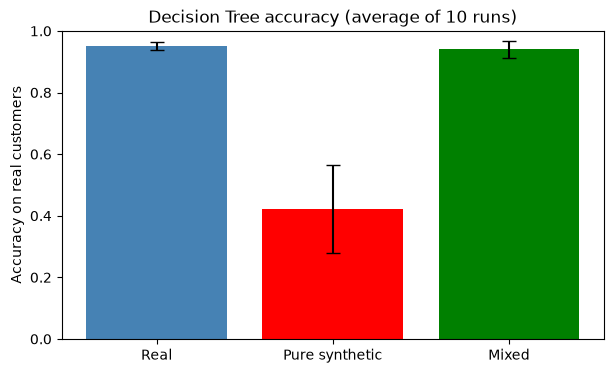

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

np.random.seed(42)
df = pd.read_csv(r"C:\Users\shiva\Downloads\archive (1).csv")
real = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values.astype(float)

scaler = StandardScaler().fit(real[:, 1:3])
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(scaler.transform(real[:, 1:3]))
labels_real = km.labels_

def fit(X): return X.mean(0), np.cov(X, rowvar=False, bias=True) + 1e-6 * np.eye(X.shape[1])
def sample(m, c, n): return np.random.multivariate_normal(m, c, n)
N, GEN, REAL_FRAC = 50, 100, 0.3

def run(mixed):
    X = real[np.random.choice(len(real), N, replace=False)]
    n_real = int(REAL_FRAC * N) if mixed else 0
    for g in range(GEN):
        m, c = fit(X)
        synth = sample(m, c, N - n_real)
        X = np.vstack([synth, real[np.random.choice(len(real), n_real, replace=False)]]) if mixed else synth
    return X

def accuracy(train_X, test_X, test_y):
    Xs = scaler.transform(train_X[:, 1:3])
    y = km.predict(Xs)                      # segment labels for the training data
    clf = DecisionTreeClassifier(max_depth=4, random_state=42).fit(Xs, y)
    return accuracy_score(test_y, clf.predict(scaler.transform(test_X[:, 1:3])))

RUNS = 10
res = {"Trained on real data": [], "Trained on pure synthetic (Gen 100)": [], "Trained on mixed (Gen 100)": []}
for r in range(RUNS):
    idx = np.random.permutation(len(real))
    tr, te = idx[:N], idx[N:]               # 50 real for training, 150 real for testing
    res["Trained on real data"].append(accuracy(real[tr], real[te], labels_real[te]))
    res["Trained on pure synthetic (Gen 100)"].append(accuracy(run(False), real[te], labels_real[te]))
    res["Trained on mixed (Gen 100)"].append(accuracy(run(True), real[te], labels_real[te]))

table = pd.DataFrame({"Model": list(res.keys()),
                      "Mean accuracy": [round(np.mean(v), 3) for v in res.values()],
                      "Std": [round(np.std(v), 3) for v in res.values()]})
print(table)

plt.figure(figsize=(7, 4))
plt.bar(["Real", "Pure synthetic", "Mixed"], [np.mean(v) for v in res.values()],
        yerr=[np.std(v) for v in res.values()], color=["steelblue", "red", "green"], capsize=5)
plt.ylabel("Accuracy on real customers"); plt.ylim(0, 1)
plt.title("Decision Tree accuracy (average of 10 runs)"); plt.show()

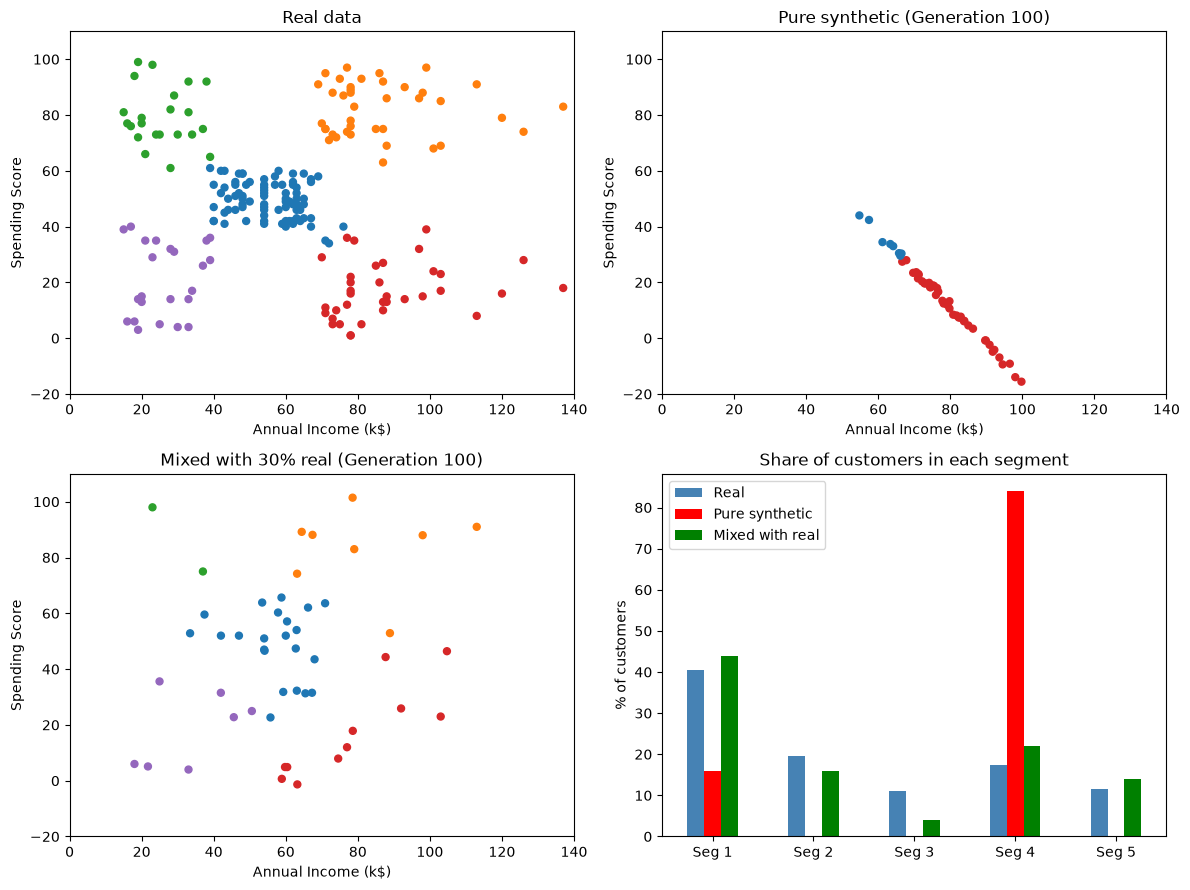

       Real  Pure synthetic  Mixed with real
Seg 1  40.5            16.0             44.0
Seg 2  19.5             0.0             16.0
Seg 3  11.0             0.0              4.0
Seg 4  17.5            84.0             22.0
Seg 5  11.5             0.0             14.0
Segments with at least 5% of customers: {'Real': 5, 'Pure': 2, 'Mixed': 4}


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
df = pd.read_csv(r"C:\Users\shiva\Downloads\archive (1).csv")
real = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values.astype(float)

# KMeans model trained on the real data
scaler = StandardScaler().fit(real[:, 1:3])
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(scaler.transform(real[:, 1:3]))

# recursive training simulation
def fit(X): return X.mean(0), np.cov(X, rowvar=False, bias=True) + 1e-6 * np.eye(X.shape[1])
def sample(m, c, n): return np.random.multivariate_normal(m, c, n)
N, GEN, REAL_FRAC = 50, 100, 0.3

def run(mixed):
    X = real[np.random.choice(len(real), N, replace=False)]
    n_real = int(REAL_FRAC * N) if mixed else 0
    for g in range(GEN):
        m, c = fit(X)
        synth = sample(m, c, N - n_real)
        if mixed:
            X = np.vstack([synth, real[np.random.choice(len(real), n_real, replace=False)]])
        else:
            X = synth
    return X

pure100, mixed100 = run(False), run(True)

def labels_of(X): return km.predict(scaler.transform(X[:, 1:3]))
def share(X): return np.bincount(labels_of(X), minlength=5) / len(X) * 100

# combined 4-panel graph
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

sets = [(real, "Real data"),
        (pure100, "Pure synthetic (Generation 100)"),
        (mixed100, "Mixed with 30% real (Generation 100)")]
for a, (X, title) in zip([ax[0, 0], ax[0, 1], ax[1, 0]], sets):
    a.scatter(X[:, 1], X[:, 2], c=labels_of(X), cmap="tab10", vmin=0, vmax=9, s=25)
    a.set_title(title)
    a.set_xlabel("Annual Income (k$)")
    a.set_ylabel("Spending Score")
    a.set_xlim(0, 140); a.set_ylim(-20, 110)

share_df = pd.DataFrame({"Real": share(real),
                         "Pure synthetic": share(pure100),
                         "Mixed with real": share(mixed100)},
                        index=[f"Seg {i+1}" for i in range(5)])
share_df.plot(kind="bar", ax=ax[1, 1], color=["steelblue", "red", "green"])
ax[1, 1].set_title("Share of customers in each segment")
ax[1, 1].set_ylabel("% of customers")
ax[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(share_df.round(1))
print("Segments with at least 5% of customers:",
      {"Real": int((share(real) >= 5).sum()),
       "Pure": int((share(pure100) >= 5).sum()),
       "Mixed": int((share(mixed100) >= 5).sum())})

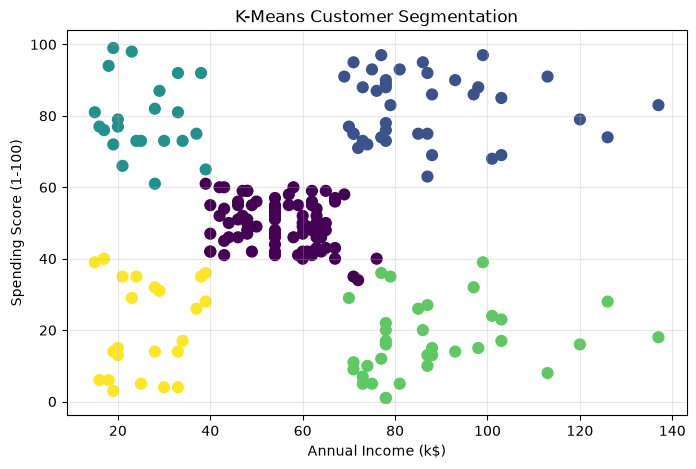

In [5]:
# ---------- Graph 2: K-Means Customer Segmentation ----------
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=60)
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segmentation"); plt.grid(alpha=0.3)
plt.show()

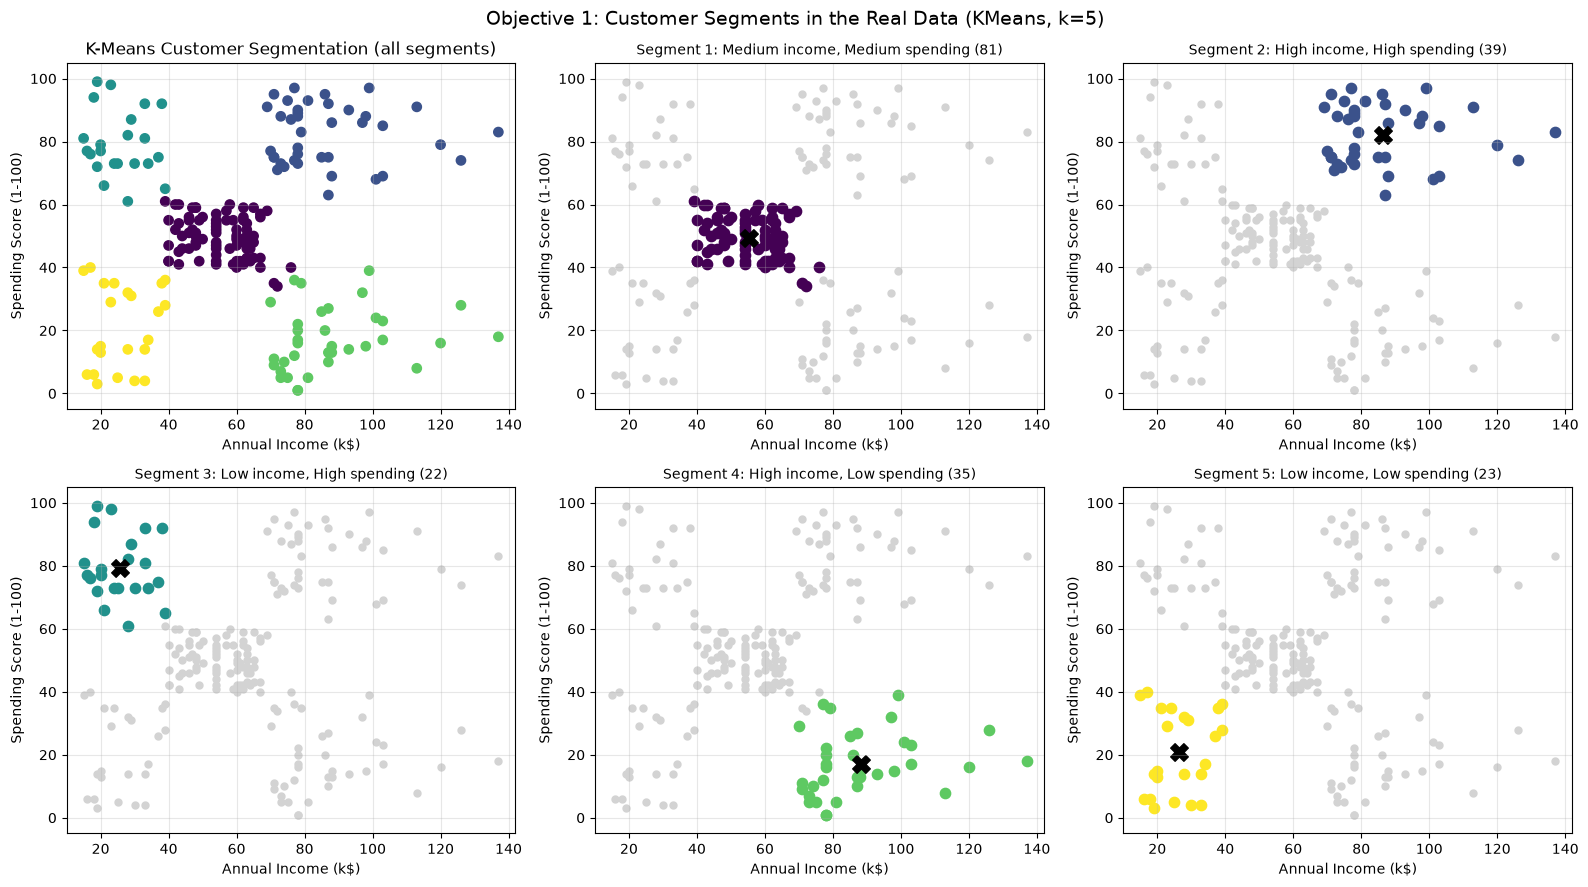

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ---------- data and model ----------

X = df[["Annual Income (k$)", "Spending Score (1-100)"]].values.astype(float)
Xs = StandardScaler().fit_transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(Xs)
labels = km.labels_
centres = np.array([X[labels == k].mean(axis=0) for k in range(5)])
colors = plt.cm.viridis(np.linspace(0, 1, 5))
sizes = np.bincount(labels, minlength=5)

def name_of(inc, spd):
    i = "High" if inc >= 70 else "Low" if inc <= 40 else "Medium"
    s = "High" if spd >= 65 else "Low" if spd <= 35 else "Medium"
    return f"{i} income, {s} spending"
names = [name_of(*c) for c in centres]

XLIM, YLIM = (10, 142), (-5, 105)

# ---------- combined 6-panel figure ----------
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
ax = ax.ravel()

# Panel 1: Graph 2 (all segments together)
ax[0].scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=45)
ax[0].set_title("K-Means Customer Segmentation (all segments)")

# Panels 2 to 6: Graphs 4 to 8 (one segment each)
for k in range(5):
    a = ax[k + 1]
    a.scatter(X[labels != k, 0], X[labels != k, 1], color="lightgrey", s=25)
    a.scatter(X[labels == k, 0], X[labels == k, 1], color=colors[k], s=55)
    a.scatter(*centres[k], c="black", marker="X", s=160)
    a.set_title(f"Segment {k+1}: {names[k]} ({sizes[k]})", fontsize=10)

for a in ax:
    a.set_xlim(XLIM); a.set_ylim(YLIM)
    a.set_xlabel("Annual Income (k$)")
    a.set_ylabel("Spending Score (1-100)")
    a.grid(alpha=0.3)

plt.suptitle("Objective 1: Customer Segments in the Real Data (KMeans, k=5)", fontsize=14)
plt.tight_layout()
plt.show()